# Flight Delay Prediction Using Machine Learning

**Goal:** predict whether a US domestic flight will arrive **15 or more minutes late**
(`ArrDel15 = 1`) using only information that is known **before departure**.

**Dataset:** Kaggle *Flight Delay Dataset 2018–2022* (`Combined_Flights_2022.parquet`,
which covers January–July 2022).

**Models compared:** Logistic Regression, Decision Tree, Random Forest, Support Vector
Machine (RBF kernel) and Naive Bayes.

**Evaluation:** accuracy, precision, recall, F1 (delayed class), **macro F1** (primary),
ROC-AUC, PR-AUC and confusion matrices, with decision thresholds tuned on
out-of-fold training predictions so the test set stays untouched.

| Phase | Contents |
|---|---|
| 1 | Dataset inspection |
| 2 | Cleaning, feature engineering, sampling, exploratory analysis |
| 3 | Model training with 5-fold cross-validation |
| 4 | Threshold tuning and test-set evaluation |
| 5 | Conclusions and limitations |

## 0. Setup

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 70)
pd.set_option("display.float_format", "{:.3f}".format)

# Folder holding the Kaggle files (Combined_Flights_<YEAR>.parquet)
DATA_DIR = Path(os.environ.get("FLIGHT_DATA_DIR", "~/Desktop/archive")).expanduser()
YEAR = "2022"
SEED = 42
SAMPLE_SIZE = 200_000
SVM_TRAIN_ROWS = 25_000      # kernel SVM scales ~quadratically, so it uses a subset
TARGET = "ArrDel15"

# Chart style
BLUE, ORANGE, INK_2, GRID, SURFACE = "#2a78d6", "#eb6834", "#52514e", "#e4e3df", "#fcfcfb"
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Decision Tree": "#eb6834",
                "Random Forest": "#1baf7a", "SVM (RBF)": "#eda100", "Naive Bayes": "#e87ba4"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "figure.dpi": 110,
})
PCT = PercentFormatter(1.0, decimals=0)
print("Data folder:", DATA_DIR)

Data folder: ~/Desktop/archive


## Phase 1 — Dataset inspection

Load the full 2022 file and check its size, columns, missing values, duplicates and the
target-class distribution before committing to it.

In [2]:
raw = pd.read_parquet(DATA_DIR / f"Combined_Flights_{YEAR}.parquet")
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Memory: {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Dates: {raw['FlightDate'].min():%Y-%m-%d} to {raw['FlightDate'].max():%Y-%m-%d}")
raw.head()

Rows: 4,078,318   Columns: 61
Memory: 2.41 GB
Dates: 2022-01-01 to 2022-07-31


,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,ArrTime,ArrDelayMinutes,AirTime,CRSElapsedTime,ActualElapsedTime,Distance,Year,Quarter,Month,DayofMonth,DayOfWeek,Marketing_Airline_Network,Operated_or_Branded_Code_Share_Partners,DOT_ID_Marketing_Airline,IATA_Code_Marketing_Airline,Flight_Number_Marketing_Airline,Operating_Airline,DOT_ID_Operating_Airline,IATA_Code_Operating_Airline,Tail_Number,Flight_Number_Operating_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,DestCityName,DestState,DestStateFips,DestStateName,DestWac,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
0,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",GJT,DEN,False,False,1133,1123.000,0.000,-10.000,1228.000,0.000,40.000,72.000,65.000,212.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4301,C5,20445,C5,N21144,4301,11921,1192102,31921,"Grand Junction, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,-1.000,1100-1159,17.000,1140.000,1220.000,8.000,1245,-17.000,0.000,-2.000,1200-1259,1,0
1,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",HRL,IAH,False,False,732,728.000,0.000,-4.000,848.000,0.000,55.000,77.000,80.000,295.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4299,C5,20445,C5,N16170,4299,12206,1220605,32206,"Harlingen/San Benito, TX",TX,48,Texas,74,12266,1226603,31453,"Houston, TX",TX,48,Texas,74,0.000,-1.000,0700-0759,16.000,744.000,839.000,9.000,849,-1.000,0.000,-1.000,0800-0859,2,0
2,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1529,1514.000,0.000,-15.000,1636.000,0.000,47.000,70.000,82.000,251.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4298,C5,20445,C5,N21144,4298,11413,1141307,30285,"Durango, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,-1.000,1500-1559,21.000,1535.000,1622.000,14.000,1639,-3.000,0.000,-1.000,1600-1659,2,0
3,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",IAH,GPT,False,False,1435,1430.000,0.000,-5.000,1547.000,0.000,57.000,90.000,77.000,376.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4296,C5,20445,C5,N11184,4296,12266,1226603,31453,"Houston, TX",TX,48,Texas,74,11973,1197302,31973,"Gulfport/Biloxi, MS",MS,28,Mississippi,53,0.000,-1.000,1400-1459,16.000,1446.000,1543.000,4.000,1605,-18.000,0.000,-2.000,1600-1659,2,0
4,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1135,1135.000,0.000,0.000,1251.000,6.000,49.000,70.000,76.000,251.000,2022,2,4,4,1,UA,UA_CODESHARE,19977,UA,4295,C5,20445,C5,N17146,4295,11413,1141307,30285,"Durango, CO",CO,8,Colorado,82,11292,1129202,30325,"Denver, CO",CO,8,Colorado,82,0.000,0.000,1100-1159,19.000,1154.000,1243.000,8.000,1245,6.000,0.000,0.000,1200-1259,2,0


In [3]:
raw.dtypes.to_frame("dtype").T

,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,ArrTime,ArrDelayMinutes,AirTime,CRSElapsedTime,ActualElapsedTime,Distance,Year,Quarter,Month,DayofMonth,DayOfWeek,Marketing_Airline_Network,Operated_or_Branded_Code_Share_Partners,DOT_ID_Marketing_Airline,IATA_Code_Marketing_Airline,Flight_Number_Marketing_Airline,Operating_Airline,DOT_ID_Operating_Airline,IATA_Code_Operating_Airline,Tail_Number,Flight_Number_Operating_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,DestCityName,DestState,DestStateFips,DestStateName,DestWac,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
dtype,datetime64[us],str,str,str,bool,bool,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,str,str,int64,str,int64,str,int64,str,str,int64,int64,int64,int64,str,str,int64,str,int64,int64,int64,int64,str,str,int64,str,int64,float64,float64,str,float64,float64,float64,float64,int64,float64,float64,float64,str,int64,int64


In [4]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "share": missing / len(raw)})

,missing,share
ArrivalDelayGroups,133402,0.033
ArrDel15,133402,0.033
ArrDelayMinutes,133402,0.033
AirTime,133402,0.033
ActualElapsedTime,133402,0.033
ArrDelay,133402,0.033
TaxiIn,124242,0.030
WheelsOn,124242,0.030
ArrTime,124239,0.030
WheelsOff,122666,0.030


In [5]:
print(f"Duplicate rows: {raw.duplicated().sum():,}")
print(f"Cancelled: {raw['Cancelled'].sum():,}   Diverted: {raw['Diverted'].sum():,}")
print("\nTarget distribution (NaN = cancelled/diverted, no arrival):")
print(raw[TARGET].value_counts(dropna=False, normalize=True).rename("share"))

Duplicate rows: 0
Cancelled: 123,192   Diverted: 10,210

Target distribution (NaN = cancelled/diverted, no arrival):
ArrDel15
0.000   0.758
1.000   0.209
NaN     0.033
Name: share, dtype: float64


**Findings**

- ~4.08 million flights, 61 columns, no duplicate rows.
- Missing values (~3%) come almost entirely from cancelled and diverted flights, which
  have no arrival — so no label. Dropping them removes nearly all gaps.
- Among completed flights about **21.7% are delayed**: an imbalance of roughly 3.6 : 1.
  Accuracy alone would be misleading (always predicting "on time" scores ~78%), so we
  focus on **macro F1** and the **delayed-class F1**.
- Many columns are only known **after** take-off (`DepDelay`, `TaxiOut`, `WheelsOff`,
  `AirTime`, `ArrTime`, …). Using them would leak the answer, so they are excluded.

## Phase 2 — Cleaning, feature engineering and exploration

### 2.1 Cleaning

In [6]:
LEAKAGE_COLUMNS = [
    "DepTime", "DepDelay", "DepDelayMinutes", "DepDel15", "DepartureDelayGroups",
    "TaxiOut", "WheelsOff", "WheelsOn", "TaxiIn", "ArrTime", "ArrDelay",
    "ArrDelayMinutes", "ArrivalDelayGroups", "AirTime", "ActualElapsedTime",
    "DivAirportLandings",
]
KEEP = ["FlightDate", "Airline", "Origin", "Dest", "Cancelled", "Diverted",
        "CRSDepTime", "CRSArrTime", "CRSElapsedTime", "Distance", "DistanceGroup",
        "Quarter", "Month", "DayofMonth", "DayOfWeek", "Tail_Number", TARGET]
assert not set(KEEP) & set(LEAKAGE_COLUMNS)

df = raw[KEEP]
df = df[~df["Cancelled"] & ~df["Diverted"]].drop(columns=["Cancelled", "Diverted"])
df = df.dropna(subset=[TARGET, "CRSElapsedTime"]).drop_duplicates()
del raw
print(f"Completed flights after cleaning: {len(df):,}")
print(f"Delayed rate: {df[TARGET].mean():.2%}")

Completed flights after cleaning: 3,944,915
Delayed rate: 21.65%


### 2.2 Feature engineering

All features can be computed from the **published schedule**, so they are available
before departure. Airport traffic and the aircraft's leg of the day are computed on the
full year *before* sampling so they reflect real schedule volumes.

In [7]:
df["dep_hour"] = (df["CRSDepTime"] // 100).clip(0, 23)
df["arr_hour"] = (df["CRSArrTime"] // 100).clip(0, 23)
df["is_weekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)
df["overnight"] = (df["CRSArrTime"] < df["CRSDepTime"]).astype(int)

# Congestion: scheduled flights at each airport that day / hour
df["origin_daily_flights"] = df.groupby(["Origin", "FlightDate"])["Origin"].transform("size")
df["dest_daily_flights"] = df.groupby(["Dest", "FlightDate"])["Dest"].transform("size")
df["origin_hourly_flights"] = df.groupby(["Origin", "FlightDate", "dep_hour"])["Origin"].transform("size")

# Which flight of the day this aircraft is flying (delays carry over between legs)
leg = df.groupby(["Tail_Number", "FlightDate"])["CRSDepTime"].rank(method="first")
df["aircraft_leg_of_day"] = leg.fillna(1).astype(int)

# Days to the nearest US federal holiday (capped at 30)
holidays = USFederalHolidayCalendar().holidays(f"{int(YEAR) - 1}-12-01", f"{int(YEAR) + 1}-01-31")
dates = pd.Series(df["FlightDate"].unique())
gap = dates.map(lambda d: np.abs((holidays - d).days).min())
df["days_to_holiday"] = df["FlightDate"].map(dict(zip(dates, gap))).clip(upper=30)

df[TARGET] = df[TARGET].astype(int)
df.drop(columns=["FlightDate", "Tail_Number", "CRSDepTime", "CRSArrTime"]).head()

,Airline,Origin,Dest,CRSElapsedTime,Distance,DistanceGroup,Quarter,Month,DayofMonth,DayOfWeek,ArrDel15,dep_hour,arr_hour,is_weekend,overnight,origin_daily_flights,dest_daily_flights,origin_hourly_flights,aircraft_leg_of_day,days_to_holiday
0,"Commutair Aka Champlain Enterprises, Inc.",GJT,DEN,72.000,212.000,1,2,4,4,1,0,11,12,0,0,9,726,2,3,30
1,"Commutair Aka Champlain Enterprises, Inc.",HRL,IAH,77.000,295.000,2,2,4,4,1,0,7,8,0,0,12,382,1,1,30
2,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,70.000,251.000,2,2,4,4,1,0,15,16,0,0,9,726,1,5,30
3,"Commutair Aka Champlain Enterprises, Inc.",IAH,GPT,90.000,376.000,2,2,4,4,1,0,14,16,0,0,385,10,49,4,30
4,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,70.000,251.000,2,2,4,4,1,0,11,12,0,0,9,726,1,2,30


### 2.3 Stratified sample

3.9 million rows is more than the SVM can handle, so we draw a **200,000-flight
stratified sample** that keeps the 21.65% delay rate exactly. All models use it, so the
comparison is fair.

In [8]:
CATEGORICAL = ["Airline", "Origin", "Dest"]
# Month is NOT a feature: with a chronological split the test months never appear in training
NUMERIC = ["CRSElapsedTime", "Distance", "DayofMonth", "DayOfWeek",
           "dep_hour", "arr_hour", "is_weekend", "overnight",
           "origin_daily_flights", "dest_daily_flights", "origin_hourly_flights",
           "aircraft_leg_of_day", "days_to_holiday"]
FEATURES = CATEGORICAL + NUMERIC

frac = SAMPLE_SIZE / len(df)
sample = (df[FEATURES + ["FlightDate", "Month", "DistanceGroup", "Quarter", TARGET]]
          .groupby(TARGET, group_keys=False).sample(frac=frac, random_state=SEED)
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
full_rate = df[TARGET].mean()
del df
print(f"Sample: {len(sample):,} rows, delayed rate {sample[TARGET].mean():.2%} (full data {full_rate:.2%})")
print(f"Missing values in sample: {sample.isna().sum().sum()}")

Sample: 200,000 rows, delayed rate 21.65% (full data 21.65%)
Missing values in sample: 0


### 2.4 Exploratory data analysis

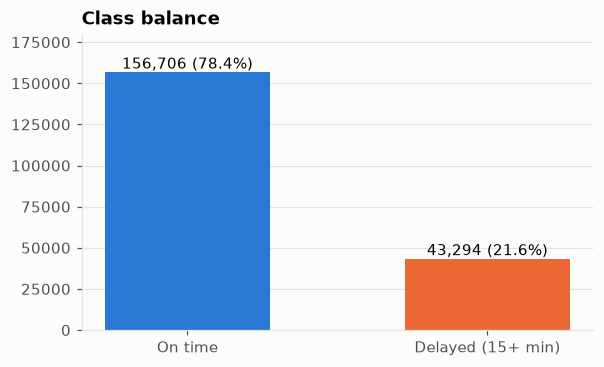

In [9]:
OVERALL = sample[TARGET].mean()

def rate_bar(ax, series, labels=None, horizontal=False, title="", xlabel=""):
    labels = labels if labels is not None else series.index.astype(str)
    if horizontal:
        ax.barh(labels, series.values, color=BLUE, height=0.6)
        ax.axvline(OVERALL, color=INK_2, ls="--", lw=1, label=f"Overall ({OVERALL:.1%})")
        ax.xaxis.set_major_formatter(PCT); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Share of flights delayed")
    else:
        ax.bar(labels, series.values, color=BLUE, width=0.65)
        ax.axhline(OVERALL, color=INK_2, ls="--", lw=1, label=f"Overall ({OVERALL:.1%})")
        ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
        ax.set_ylabel("Share of flights delayed"); ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9, loc="lower right" if horizontal else "upper left")

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = sample[TARGET].value_counts().sort_index()
ax.bar(["On time", "Delayed (15+ min)"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,} ({n / len(sample):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15); ax.set_title("Class balance"); ax.grid(axis="x", visible=False)
plt.show()

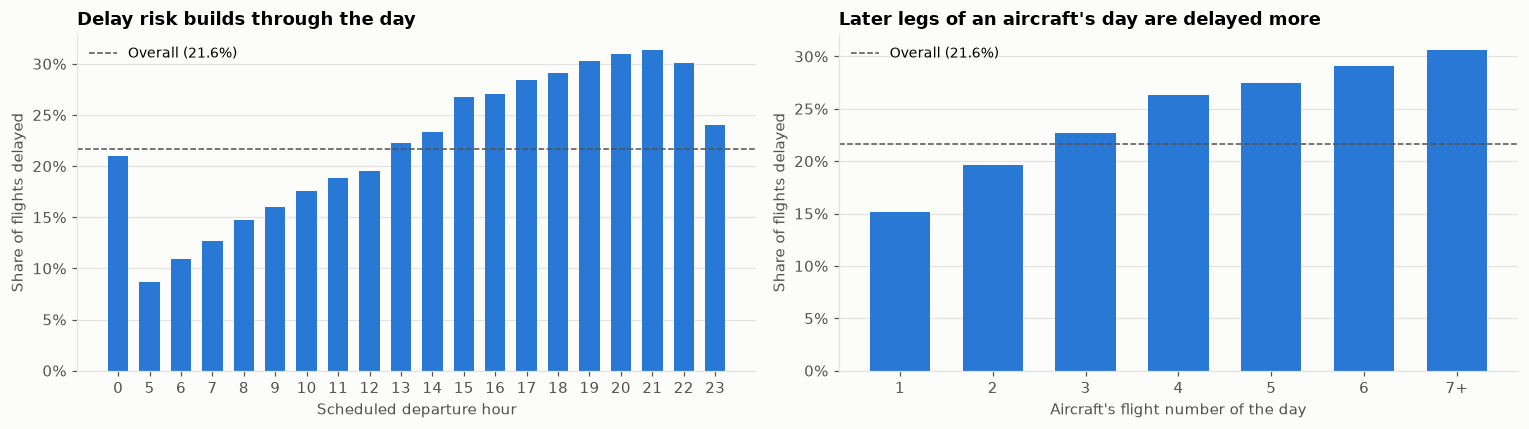

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_hour = sample.groupby("dep_hour")[TARGET].agg(["mean", "size"])
rate_bar(axes[0], by_hour.loc[by_hour["size"] >= 200, "mean"],
         title="Delay risk builds through the day", xlabel="Scheduled departure hour")
leg = sample.groupby(sample["aircraft_leg_of_day"].clip(upper=7))[TARGET].mean()
rate_bar(axes[1], leg, labels=[str(i) if i < 7 else "7+" for i in leg.index],
         title="Later legs of an aircraft's day are delayed more",
         xlabel="Aircraft's flight number of the day")
plt.tight_layout(); plt.show()

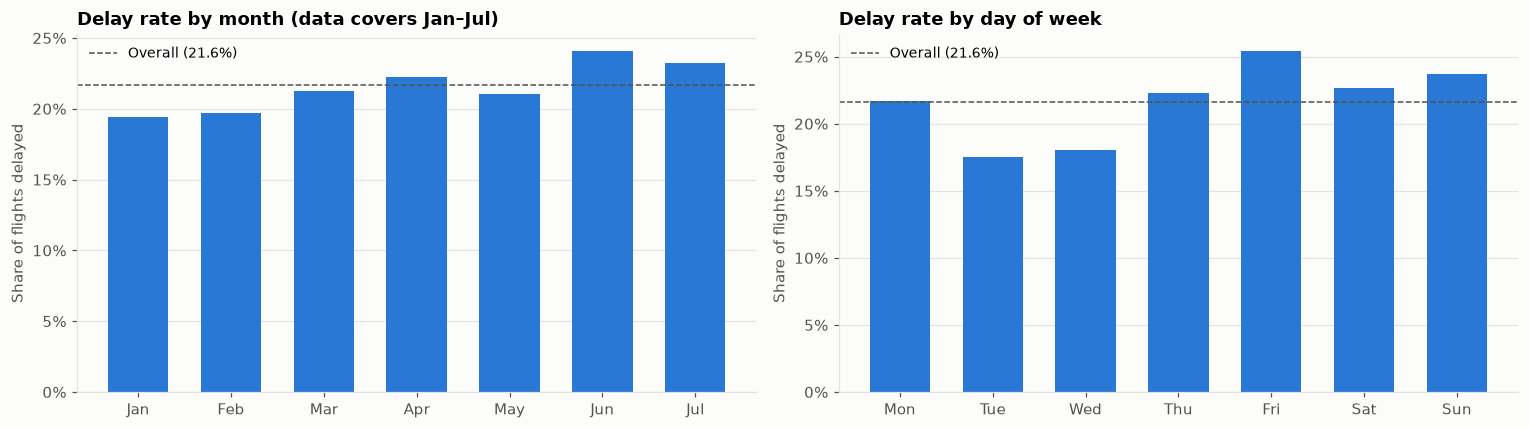

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = sample.groupby("Month")[TARGET].mean()
rate_bar(axes[0], by_month, labels=[months[m - 1] for m in by_month.index],
         title="Delay rate by month (data covers Jan–Jul)")
by_dow = sample.groupby("DayOfWeek")[TARGET].mean()
rate_bar(axes[1], by_dow, labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
         title="Delay rate by day of week")
plt.tight_layout(); plt.show()

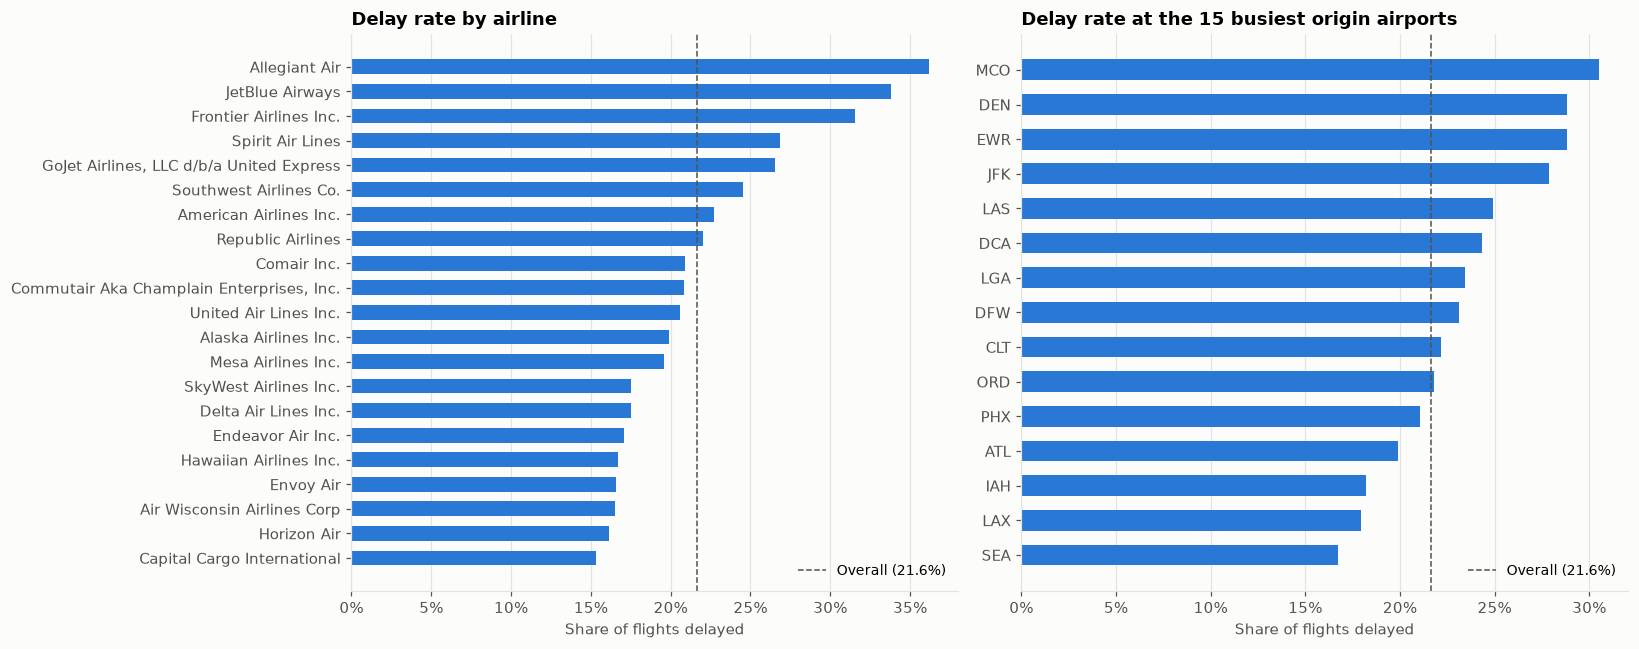

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
by_airline = sample.groupby("Airline")[TARGET].agg(["mean", "size"])
rate_bar(axes[0], by_airline[by_airline["size"] >= 500]["mean"].sort_values(), horizontal=True,
         title="Delay rate by airline")
top = sample["Origin"].value_counts().head(15).index
rate_bar(axes[1], sample[sample["Origin"].isin(top)].groupby("Origin")[TARGET].mean().sort_values(),
         horizontal=True, title="Delay rate at the 15 busiest origin airports")
plt.tight_layout(); plt.show()

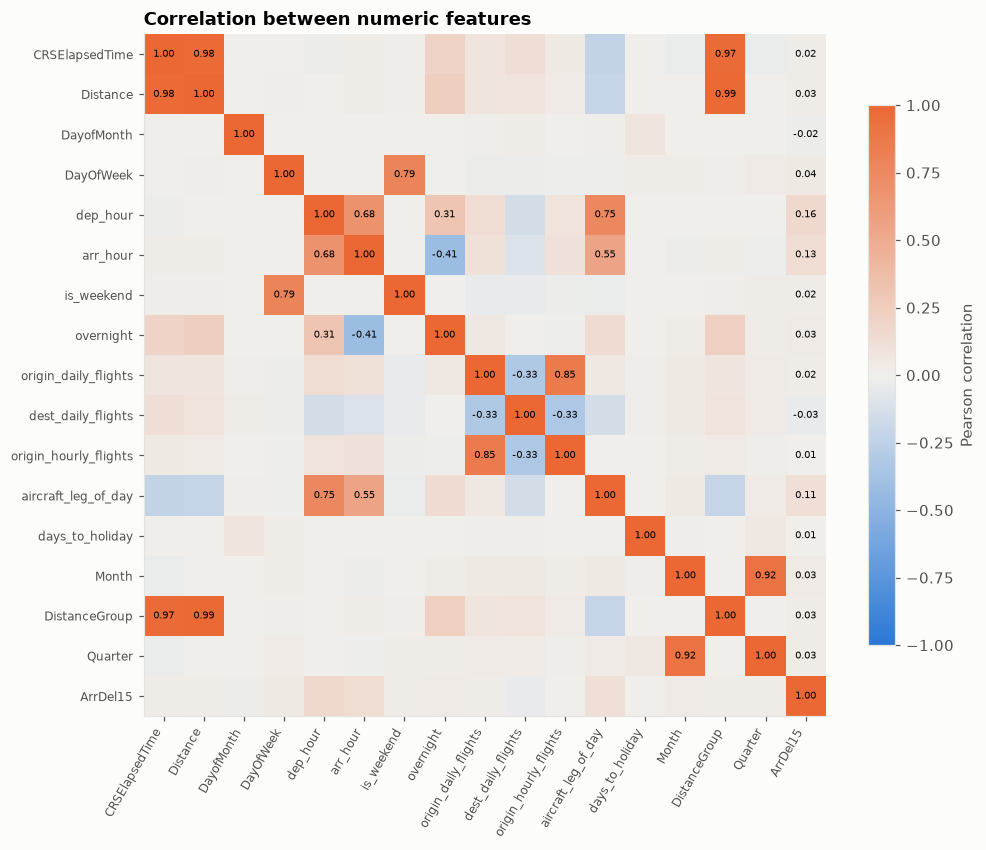

,corr with ArrDel15
dep_hour,0.161
arr_hour,0.129
aircraft_leg_of_day,0.114
DayOfWeek,0.041
Month,0.034
overnight,0.034
dest_daily_flights,-0.032
Quarter,0.029
DistanceGroup,0.028
Distance,0.027


In [13]:
corr = sample.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap=LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE]),
               vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iat[i, j]) >= 0.3 or corr.columns[j] == TARGET:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson correlation")
ax.set_title("Correlation between numeric features"); plt.show()

corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).to_frame("corr with ArrDel15")

**EDA findings**

- **Time of day** is the strongest single signal: ~9% of 5 am departures are late vs ~31% around 9 pm.
- **Aircraft leg of the day:** 15% on the first flight, rising to ~31% by the seventh — delays propagate.
- **Airlines** range from ~15% to ~36%; **airports** such as MCO, DEN and EWR are worst.
- `Distance`, `DistanceGroup` and `CRSElapsedTime` correlate at 0.97–0.99, and `Quarter`
  with `Month` at 0.92, so `DistanceGroup` is **not** used as a model feature.
- `Month` and `Quarter` are also left out: under the chronological split in Phase 3 the test
  months (June–July) never appear in training, so a month effect cannot be learned for them.
- Each single feature is weak (|r| ≤ 0.16), so realistic macro F1 scores are around 0.55–0.65.

## Phase 3 — Model training

- **Chronological split:** train on **January–May**, test on **June–July**. The goal is to
  predict *future* flights, so the model must never see the test period while training.
  (A random 80/20 split mixes the same days into train and test and gives optimistic
  scores; `scripts/07_compare_splits.py` measures the difference.) The test set is not used
  until Phase 4.
- Each model is a `Pipeline`, so encoders are fitted only on training folds (no leakage):
  - Logistic Regression and SVM: one-hot encoding of airline/airports + standardised numerics.
  - Decision Tree, Random Forest and Naive Bayes: cross-fitted **target encoding** of
    airline/airports (one number per category) + numerics.
- `class_weight="balanced"` compensates for the 3.6 : 1 imbalance.
- **5-fold stratified cross-validation** on the training set. The out-of-fold probabilities
  are kept for threshold tuning in Phase 4.

In [14]:
# Test = the last two calendar months in the data
cutoff = (sample["FlightDate"].max().to_period("M") - 1).to_timestamp()
train, test = sample[sample["FlightDate"] < cutoff], sample[sample["FlightDate"] >= cutoff]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {train['FlightDate'].min():%Y-%m-%d} to {train['FlightDate'].max():%Y-%m-%d}  "
      f"{len(train):,} flights, {y_train.mean():.2%} delayed")
print(f"Test:  {test['FlightDate'].min():%Y-%m-%d} to {test['FlightDate'].max():%Y-%m-%d}  "
      f"{len(test):,} flights, {y_test.mean():.2%} delayed")

Train: 2022-01-01 to 2022-05-31  139,780 flights, 20.79% delayed
Test:  2022-06-01 to 2022-07-31  60,220 flights, 23.64% delayed


In [15]:
def one_hot_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CATEGORICAL),
        ("num", StandardScaler(), NUMERIC)])

def target_enc_prep(scale=False):
    return ColumnTransformer([
        ("cat", TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=SEED)), CATEGORICAL),
        ("num", StandardScaler() if scale else "passthrough", NUMERIC)])

models = {
    "Logistic Regression": Pipeline([
        ("prep", one_hot_prep()),
        ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))]),
    "Decision Tree": Pipeline([
        ("prep", target_enc_prep()),
        ("clf", DecisionTreeClassifier(max_depth=12, min_samples_leaf=50,
                                       class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([
        ("prep", target_enc_prep()),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=18, min_samples_leaf=5,
                                       max_features="sqrt", class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=SEED))]),
    # Platt (sigmoid) calibration gives the SVM probabilities for ROC-AUC and thresholds
    "SVM (RBF)": Pipeline([
        ("prep", one_hot_prep()),
        ("clf", CalibratedClassifierCV(
            SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED),
            method="sigmoid", ensemble=False))]),
    "Naive Bayes": Pipeline([
        ("prep", target_enc_prep(scale=True)),
        ("clf", GaussianNB())]),
}

In [16]:
SCORING = {"accuracy": "accuracy", "precision_delayed": "precision", "recall_delayed": "recall",
           "f1_delayed": "f1", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows, oof = [], {}

for name, pipe in models.items():
    Xt, yt = X_train, y_train
    if name.startswith("SVM"):
        Xt, _, yt, _ = train_test_split(X_train, y_train, train_size=SVM_TRAIN_ROWS,
                                        stratify=y_train, random_state=SEED)
    start = time.time()
    scores = cross_validate(pipe, Xt, yt, cv=cv, scoring=SCORING,
                            return_estimator=True, return_indices=True)
    # Out-of-fold probability for each training row, from the fold model that did not see it
    proba = np.empty(len(Xt))
    for est, idx in zip(scores["estimator"], scores["indices"]["test"]):
        proba[idx] = est.predict_proba(Xt.iloc[idx])[:, 1]
    oof[name] = (yt.to_numpy(), proba)

    pipe.fit(Xt, yt)   # final model on all its training rows
    row = {"Model": name, "Train rows": len(Xt)}
    for m in SCORING:
        row[m] = scores[f"test_{m}"].mean()
    row["macro F1 std"] = scores["test_f1_macro"].std()
    row["seconds"] = time.time() - start
    cv_rows.append(row)
    print(f"{name:<20} CV macro F1 {row['f1_macro']:.3f} ± {row['macro F1 std']:.3f}  ({row['seconds']:.0f}s)")

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results

Logistic Regression  CV macro F1 0.556 ± 0.001  (6s)


Decision Tree        CV macro F1 0.561 ± 0.004  (4s)


Random Forest        CV macro F1 0.617 ± 0.002  (65s)


SVM (RBF)            CV macro F1 0.449 ± 0.003  (490s)


Naive Bayes          CV macro F1 0.549 ± 0.004  (1s)


,Train rows,accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,macro F1 std,seconds
Model,,,,,,,,,
Logistic Regression,139780,0.615,0.293,0.604,0.395,0.556,0.650,0.001,5.912
Decision Tree,139780,0.628,0.295,0.570,0.389,0.561,0.647,0.004,4.490
Random Forest,139780,0.776,0.445,0.316,0.369,0.617,0.695,0.002,64.917
SVM (RBF),25000,0.792,0.515,0.007,0.014,0.449,0.657,0.003,490.196
Naive Bayes,139780,0.760,0.352,0.184,0.241,0.549,0.630,0.004,1.101


These cross-validation scores use the default 0.5 threshold. The calibrated SVM and
Naive Bayes rarely output probabilities above 0.5, so they look weak here — Phase 4 fixes
this by tuning each model's threshold.

## Phase 4 — Threshold tuning and test-set evaluation

### 4.1 Threshold tuning (training data only)

For each model, choose the threshold that maximises **macro F1 on the out-of-fold
training predictions**. The test set is not used to choose anything.

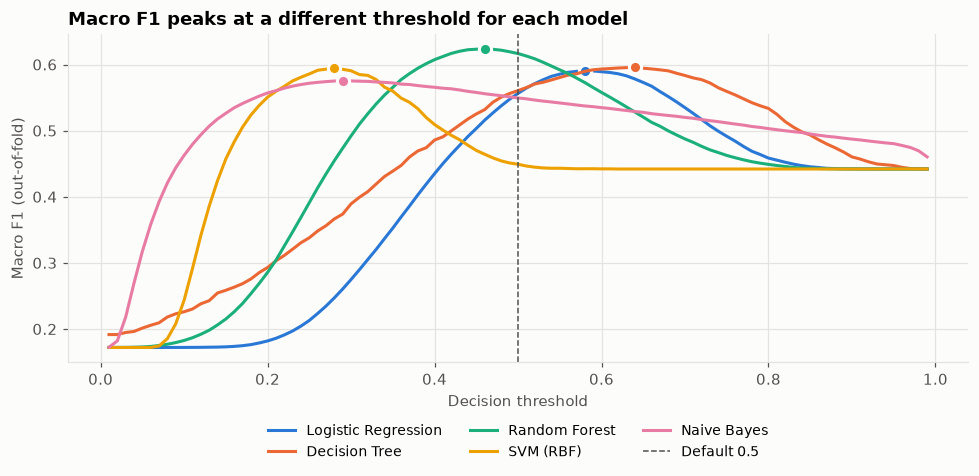

,tuned threshold
Logistic Regression,0.580
Decision Tree,0.640
Random Forest,0.460
SVM (RBF),0.280
Naive Bayes,0.290


In [17]:
THRESHOLDS = np.round(np.arange(0.01, 0.991, 0.01), 2)
best_threshold, curves = {}, {}
for name, (yt, proba) in oof.items():
    curves[name] = np.array([f1_score(yt, proba >= t, average="macro") for t in THRESHOLDS])
    best_threshold[name] = float(THRESHOLDS[curves[name].argmax()])

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, curve in curves.items():
    ax.plot(THRESHOLDS, curve, color=MODEL_COLORS[name], lw=2, label=name)
    ax.plot(best_threshold[name], curve.max(), "o", ms=8, color=MODEL_COLORS[name], mec=SURFACE, mew=2)
ax.axvline(0.5, color=INK_2, ls="--", lw=1, label="Default 0.5")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Macro F1 (out-of-fold)")
ax.set_title("Macro F1 peaks at a different threshold for each model")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()
pd.Series(best_threshold, name="tuned threshold").to_frame()

### 4.2 Test-set results

In [18]:
def evaluate(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return {"threshold": t,
            "accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "precision_delayed": precision_score(y_true, pred),
            "recall_delayed": recall_score(y_true, pred),
            "f1_delayed": f1_score(y_true, pred),
            "f1_macro": f1_score(y_true, pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

def bootstrap_ci(y_true, pred, n=500):
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(y_true), size=(n, len(y_true)))
    return np.percentile([f1_score(y_true[i], pred[i], average="macro") for i in idx], [2.5, 97.5])

y_true = y_test.to_numpy()
test_proba = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in models.items()}
default_res = pd.DataFrame({n: evaluate(y_true, p, 0.5) for n, p in test_proba.items()}).T
tuned_res = pd.DataFrame({n: evaluate(y_true, p, best_threshold[n]) for n, p in test_proba.items()}).T
for name, p in test_proba.items():
    lo, hi = bootstrap_ci(y_true, (p >= best_threshold[name]).astype(int))
    tuned_res.loc[name, "macro F1 95% CI"] = f"{lo:.3f}–{hi:.3f}"
order = tuned_res.sort_values("f1_macro", ascending=False).index

print("Default threshold 0.5:")
display(default_res.loc[order])
print("Tuned thresholds:")
tuned_res.loc[order]

Default threshold 0.5:


,threshold,accuracy,balanced_accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,pr_auc
Logistic Regression,0.500,0.630,0.604,0.332,0.555,0.415,0.573,0.643,0.351
Random Forest,0.500,0.740,0.562,0.408,0.225,0.290,0.565,0.636,0.348
Naive Bayes,0.500,0.732,0.541,0.364,0.179,0.240,0.539,0.637,0.327
SVM (RBF),0.500,0.763,0.501,0.444,0.004,0.008,0.437,0.617,0.322
Decision Tree,0.500,0.579,0.565,0.290,0.537,0.376,0.530,0.585,0.297


Tuned thresholds:


,threshold,accuracy,balanced_accuracy,precision_delayed,recall_delayed,f1_delayed,f1_macro,roc_auc,pr_auc,macro F1 95% CI
Logistic Regression,0.580,0.713,0.582,0.379,0.333,0.355,0.585,0.643,0.351,0.581–0.589
Random Forest,0.460,0.717,0.578,0.381,0.315,0.345,0.582,0.636,0.348,0.578–0.586
Naive Bayes,0.290,0.685,0.576,0.345,0.369,0.356,0.574,0.637,0.327,0.570–0.578
SVM (RBF),0.280,0.704,0.564,0.352,0.299,0.323,0.567,0.617,0.322,0.563–0.571
Decision Tree,0.640,0.690,0.551,0.324,0.286,0.304,0.552,0.585,0.297,0.548–0.557


In [19]:
for name in order:
    pred = (test_proba[name] >= best_threshold[name]).astype(int)
    print(f"=== {name} (threshold {best_threshold[name]:.2f}) ===")
    print(classification_report(y_true, pred, target_names=["On time", "Delayed"], digits=3))

=== Logistic Regression (threshold 0.58) ===
              precision    recall  f1-score   support

     On time      0.801     0.831     0.816     45986
     Delayed      0.379     0.333     0.355     14234

    accuracy                          0.713     60220
   macro avg      0.590     0.582     0.585     60220
weighted avg      0.701     0.713     0.707     60220

=== Random Forest (threshold 0.46) ===
              precision    recall  f1-score   support

     On time      0.799     0.842     0.820     45986
     Delayed      0.381     0.315     0.345     14234

    accuracy                          0.717     60220
   macro avg      0.590     0.578     0.582     60220
weighted avg      0.700     0.717     0.707     60220

=== Naive Bayes (threshold 0.29) ===
              precision    recall  f1-score   support

     On time      0.800     0.783     0.792     45986
     Delayed      0.345     0.369     0.356     14234

    accuracy                          0.685     60220
   macr

### 4.3 Confusion matrices

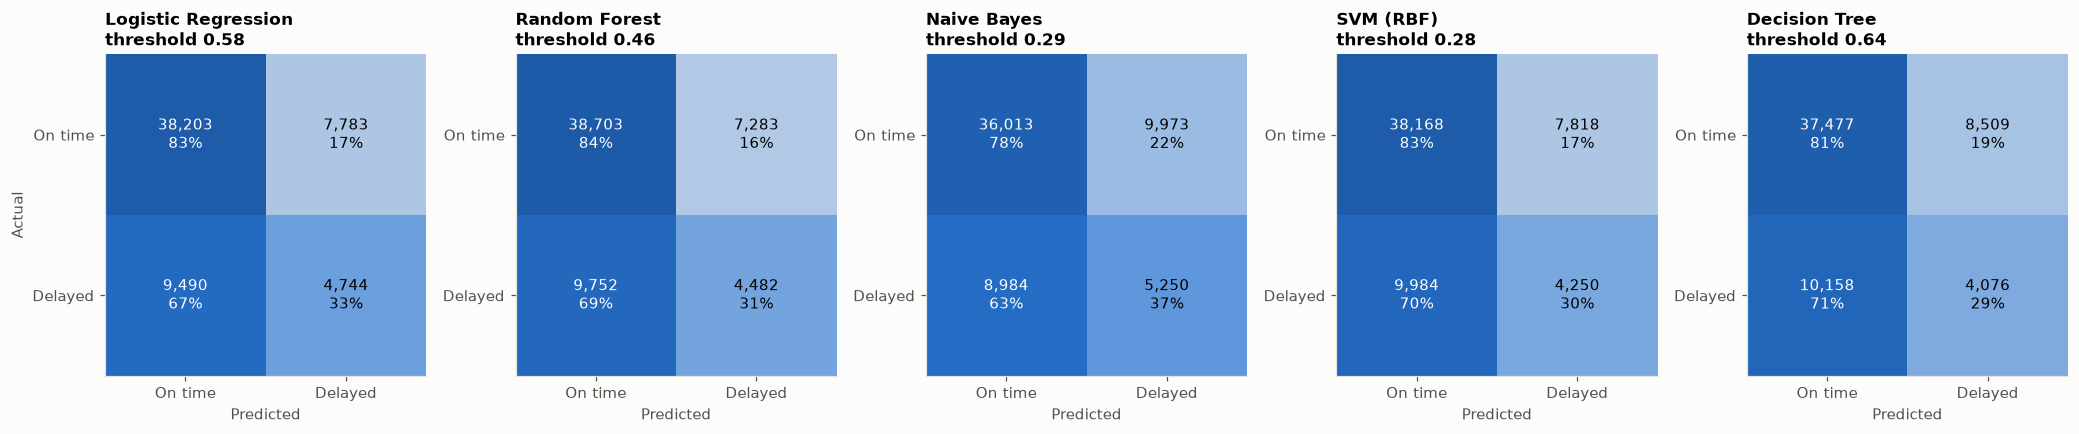

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#2a78d6", "#184f95"])
for ax, name in zip(axes, order):
    cm = confusion_matrix(y_true, test_proba[name] >= best_threshold[name])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center",
                    color="white" if share[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["On time", "Delayed"]); ax.set_yticks([0, 1], ["On time", "Delayed"])
    ax.set_xlabel("Predicted"); ax.grid(False)
    ax.set_title(f"{name}\nthreshold {best_threshold[name]:.2f}", fontsize=11)
axes[0].set_ylabel("Actual")
plt.tight_layout(); plt.show()

### 4.4 ROC and precision–recall curves

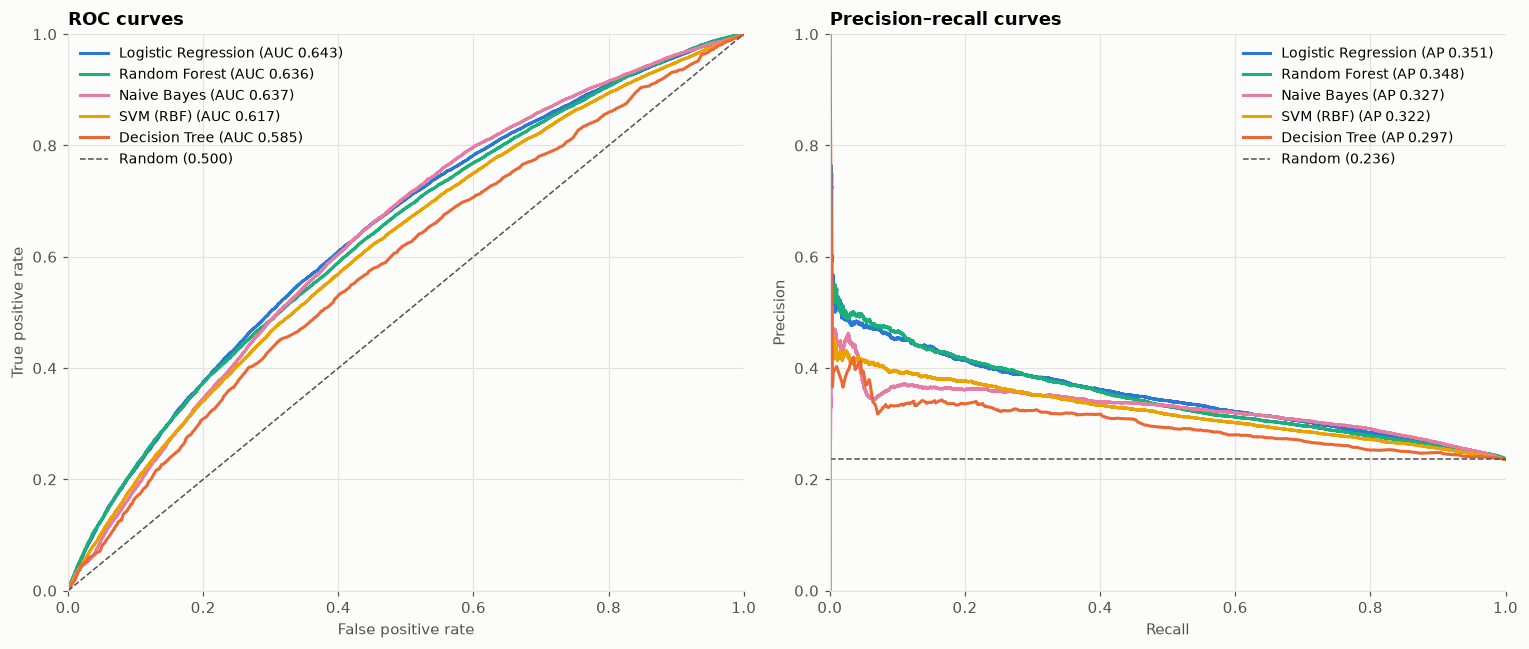

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in order:
    fpr, tpr, _ = roc_curve(y_true, test_proba[name])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], lw=2,
                 label=f"{name} (AUC {tuned_res.loc[name, 'roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_true, test_proba[name])
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], lw=2,
                 label=f"{name} (AP {tuned_res.loc[name, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1, label="Random (0.500)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves", xlim=(0, 1), ylim=(0, 1))
axes[1].axhline(y_true.mean(), color=INK_2, ls="--", lw=1, label=f"Random ({y_true.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves", xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### 4.5 Model comparison

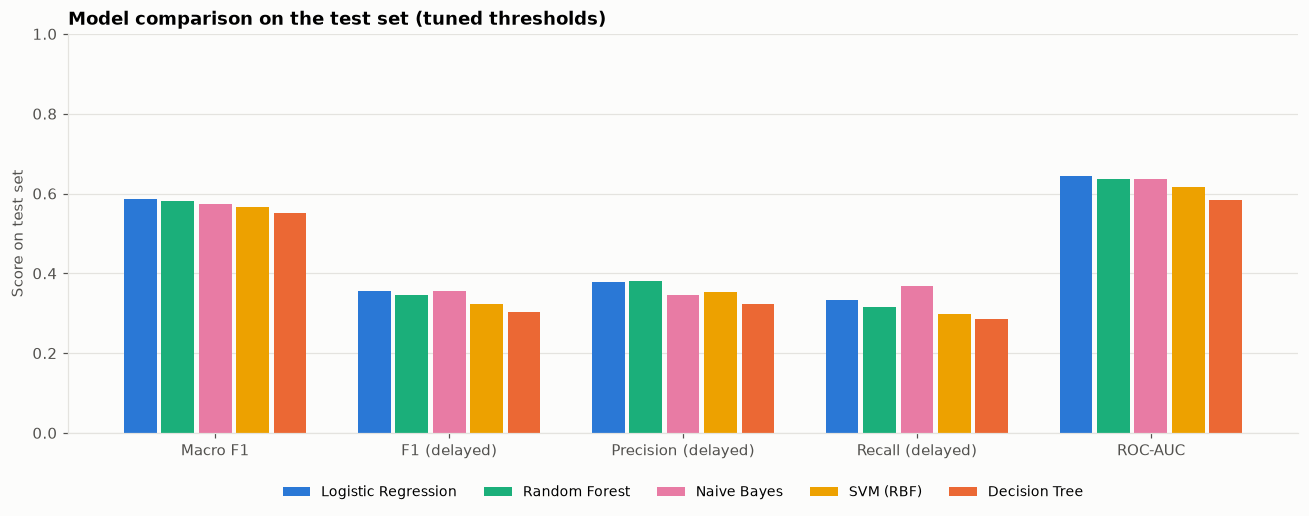

In [22]:
metric_names = {"f1_macro": "Macro F1", "f1_delayed": "F1 (delayed)", "precision_delayed": "Precision (delayed)",
                "recall_delayed": "Recall (delayed)", "roc_auc": "ROC-AUC"}
fig, ax = plt.subplots(figsize=(12, 4.8))
x, width = np.arange(len(metric_names)), 0.16
for i, name in enumerate(order):
    ax.bar(x + (i - 2) * width, tuned_res.loc[name, list(metric_names)].astype(float),
           width=width - 0.02, color=MODEL_COLORS[name], label=name)
ax.set_xticks(x, metric_names.values()); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
ax.set_ylabel("Score on test set"); ax.set_title("Model comparison on the test set (tuned thresholds)")
ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

### 4.6 Delayed-class recall and F1: choosing a threshold for a clear objective

A model outputs a delay *probability*; the threshold turns it into an alert. Lower
thresholds catch more delays (**recall** ↑) but raise more false alarms (**precision** ↓).
The right trade-off depends on what the alert is used for, so we define each objective
explicitly and choose its threshold on the **out-of-fold training predictions** (never
the test set):

| Objective | Rule | Typical use |
|---|---|---|
| `default_0.5` | fixed 0.5 | no tuning (baseline) |
| `max_macro_f1` | maximise macro F1 | balanced performance on both classes (primary) |
| `max_delayed_f1` | maximise delayed-class F1 | best single score for the delayed class |
| `recall_70%` | highest precision with recall ≥ 70% | catch most delays: warn passengers, plan spare crew |
| `precision_50%` | highest recall with precision ≥ 50% | few false alarms: costly interventions |

In [23]:
RECALL_TARGET, PRECISION_TARGET = 0.70, 0.50

def pr_curves(y, proba):
    out = {"precision": [], "recall": [], "f1_delayed": [], "f1_macro": []}
    for t in THRESHOLDS:
        pred = proba >= t
        out["precision"].append(precision_score(y, pred, zero_division=0))
        out["recall"].append(recall_score(y, pred, zero_division=0))
        out["f1_delayed"].append(f1_score(y, pred, zero_division=0))
        out["f1_macro"].append(f1_score(y, pred, average="macro", zero_division=0))
    return {k: np.array(v) for k, v in out.items()}

def choose(c, objective):
    if objective == "default_0.5":
        return 0.5
    if objective == "max_macro_f1":
        return THRESHOLDS[c["f1_macro"].argmax()]
    if objective == "max_delayed_f1":
        return THRESHOLDS[c["f1_delayed"].argmax()]
    if objective == "recall_70%":
        ok = c["recall"] >= RECALL_TARGET
        return THRESHOLDS[np.where(ok, c["precision"], -1).argmax()] if ok.any() else None
    if objective == "precision_50%":
        ok = c["precision"] >= PRECISION_TARGET
        return THRESHOLDS[np.where(ok, c["recall"], -1).argmax()] if ok.any() else None

OBJECTIVES = ["default_0.5", "max_macro_f1", "max_delayed_f1", "recall_70%", "precision_50%"]
oof_curves = {name: pr_curves(*oof[name]) for name in models}
rows = []
for name in order:
    for obj in OBJECTIVES:
        t = choose(oof_curves[name], obj)
        if t is None:
            rows.append({"model": name, "objective": obj, "threshold": np.nan})
            continue
        pred = (test_proba[name] >= t).astype(int)
        rows.append({"model": name, "objective": obj, "threshold": t,
                     "precision_delayed": precision_score(y_true, pred, zero_division=0),
                     "recall_delayed": recall_score(y_true, pred),
                     "f1_delayed": f1_score(y_true, pred),
                     "f1_macro": f1_score(y_true, pred, average="macro"),
                     "alert_rate": pred.mean()})
objective_results = pd.DataFrame(rows).set_index(["model", "objective"])
objective_results

threshold  precision_delayed  \
model               objective                                      
Logistic Regression default_0.5         0.500              0.332   
                    max_macro_f1        0.580              0.379   
                    max_delayed_f1      0.500              0.332   
                    recall_70%          0.450              0.306   
                    precision_50%       0.760              0.488   
Random Forest       default_0.5         0.500              0.408   
                    max_macro_f1        0.460              0.381   
                    max_delayed_f1      0.380              0.323   
                    recall_70%          0.340              0.302   
                    precision_50%       0.560              0.442   
Naive Bayes         default_0.5         0.500              0.364   
                    max_macro_f1        0.290              0.345   
                    max_delayed_f1      0.140              0.312   
                    recall_70%          0.120              0.303   
                    precision_50%         NaN                NaN   
SVM (RBF)           default_0.5         0.500              0.444   
                    max_macro_f1        0.280              0.352   
                    max_delayed_f1      0.180              0.295   
                    recall_70%          0.180              0.295   
                    precision_50%       0.440              0.425   
Decision Tree       default_0.5         0.500              0.290   
                    max_macro_f1        0.640              0.324   
                    max_delayed_f1      0.490              0.287   
                    recall_70%          0.420              0.276   
                    precision_50%       0.810              0.333   

                                    recall_delayed  f1_delayed  f1_macro  \
model               objective                                              
Logistic Regression default_0.5              0.555       0.415     0.573   
                    max_macro_f1             0.333       0.355     0.585   
                    max_delayed_f1           0.555       0.415     0.573   
                    recall_70%               0.686       0.424     0.533   
                    precision_50%            0.029       0.055     0.460   
Random Forest       default_0.5              0.225       0.290     0.565   
                    max_macro_f1             0.315       0.345     0.582   
                    max_delayed_f1           0.539       0.404     0.564   
                    recall_70%               0.667       0.416     0.529   
                    precision_50%            0.127       0.198     0.527   
Naive Bayes         default_0.5              0.179       0.240     0.539   
                    max_macro_f1             0.369       0.356     0.574   
                    max_delayed_f1           0.665       0.424     0.543   
                    recall_70%               0.720       0.426     0.523   
                    precision_50%              NaN         NaN       NaN   
SVM (RBF)           default_0.5              0.004       0.008     0.437   
                    max_macro_f1             0.299       0.323     0.567   
                    max_delayed_f1           0.645       0.404     0.522   
                    recall_70%               0.645       0.404     0.522   
                    precision_50%            0.022       0.042     0.453   
Decision Tree       default_0.5              0.537       0.376     0.530   
                    max_macro_f1             0.286       0.304     0.552   
                    max_delayed_f1           0.554       0.378     0.525   
                    recall_70%               0.638       0.386     0.495   
                    precision_50%            0.083       0.133     0.491   

                                    alert_rate  
model               objective                   
Logistic Regression default_0.5          0.396  

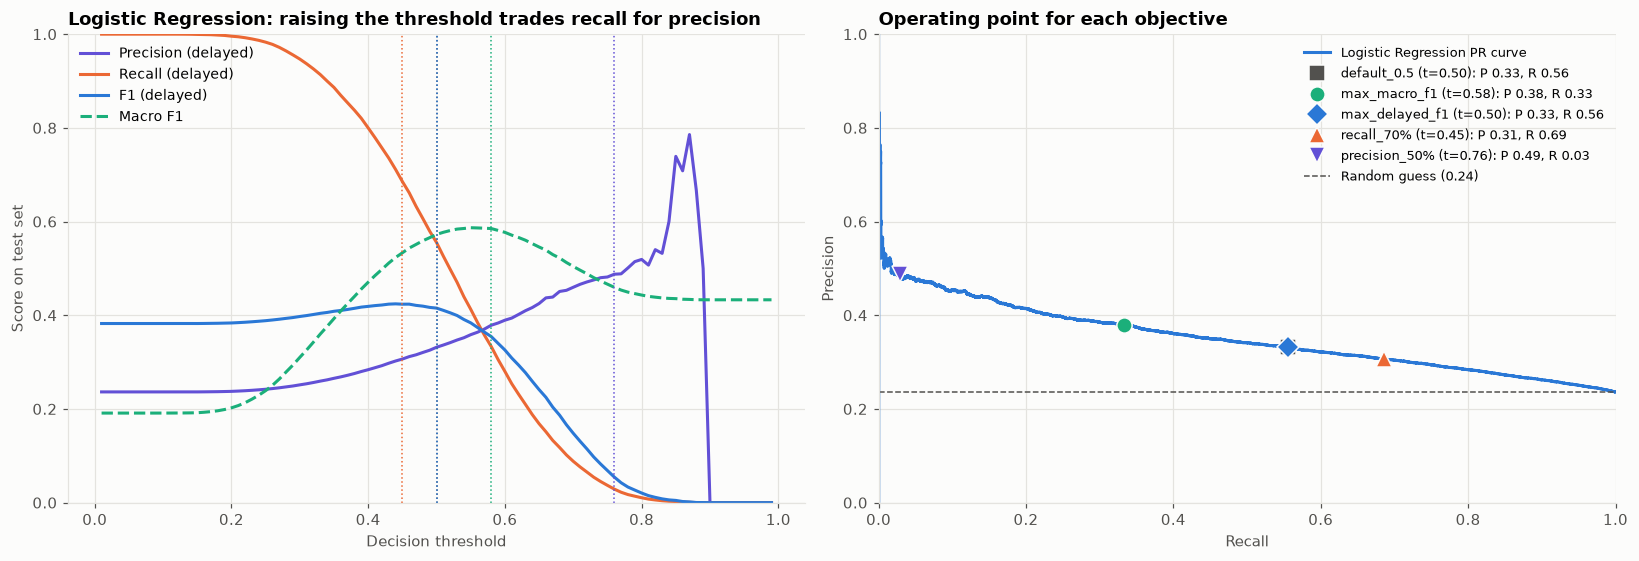

In [24]:
best = order[0]
test_c = pr_curves(y_true, test_proba[best])
styles = {"default_0.5": ("s", INK_2), "max_macro_f1": ("o", "#1baf7a"), "max_delayed_f1": ("D", "#2a78d6"),
          "recall_70%": ("^", "#eb6834"), "precision_50%": ("v", "#6250d6")}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for key, label, color, ls in [("precision", "Precision (delayed)", "#6250d6", "-"),
                              ("recall", "Recall (delayed)", "#eb6834", "-"),
                              ("f1_delayed", "F1 (delayed)", "#2a78d6", "-"),
                              ("f1_macro", "Macro F1", "#1baf7a", "--")]:
    axes[0].plot(THRESHOLDS, test_c[key], color=color, lw=2, ls=ls, label=label)
axes[0].set(xlabel="Decision threshold", ylabel="Score on test set", ylim=(0, 1),
            title=f"{best}: raising the threshold trades recall for precision")
axes[0].legend(frameon=False, fontsize=9)
prec, rec, _ = precision_recall_curve(y_true, test_proba[best])
axes[1].plot(rec, prec, color=MODEL_COLORS[best], lw=2, label=f"{best} PR curve")
for obj, (marker, color) in styles.items():
    if (best, obj) in objective_results.index and not np.isnan(objective_results.loc[(best, obj), "threshold"]):
        r = objective_results.loc[(best, obj)]
        axes[0].axvline(r["threshold"], color=color, ls=":", lw=1)
        axes[1].plot(r["recall_delayed"], r["precision_delayed"], marker, ms=10, color=color, mec=SURFACE,
                     label=f"{obj} (t={r['threshold']:.2f}): P {r['precision_delayed']:.2f}, R {r['recall_delayed']:.2f}")
axes[1].axhline(y_true.mean(), color=INK_2, ls="--", lw=1, label=f"Random guess ({y_true.mean():.2f})")
axes[1].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1), title="Operating point for each objective")
axes[1].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

**Recall / precision findings (Logistic Regression, the best model on this split)**

- At the balanced `max_macro_f1` threshold (0.58) it catches only **33% of delays** at 38% precision.
- Optimising the **delayed-class F1** instead (threshold 0.50) catches **56% of delays** at 33%
  precision: delayed F1 rises from 0.355 to **0.415**, while macro F1 falls slightly (0.585 → 0.573).
- The `recall_70%` objective catches **69% of delays**, but only 31% of its alerts are real delays
  and it flags 53% of all flights.
- A precision of 50% is essentially **unreachable**: Logistic Regression only gets there by alerting
  on 1.4% of flights (recall 3%), and Naive Bayes never reaches it.
- Precision falls steadily as recall rises, and no threshold delivers both. With pre-departure
  features alone, the model is useful for **ranking risk** and for "catch most delays" use cases
  that tolerate false alarms, not for high-confidence alerts.
- The thresholds were tuned on January–May (20.8% delayed) and applied to June–July (23.6% delayed).
  The macro-F1-optimal threshold on the test set itself would have been 0.55 instead of 0.58: the
  summer delay rate shift makes training-tuned thresholds slightly too conservative.

### 4.7 What drives the best model?

Permutation importance: how much the test ROC-AUC drops when one feature's values are
shuffled (10,000 test flights, 5 repeats). For a linear model, the collinear pair `Distance` /
`CRSElapsedTime` (r = 0.98) gets large opposing coefficients, so shuffling either one breaks
that balance. Their importance is overstated and should be read together.

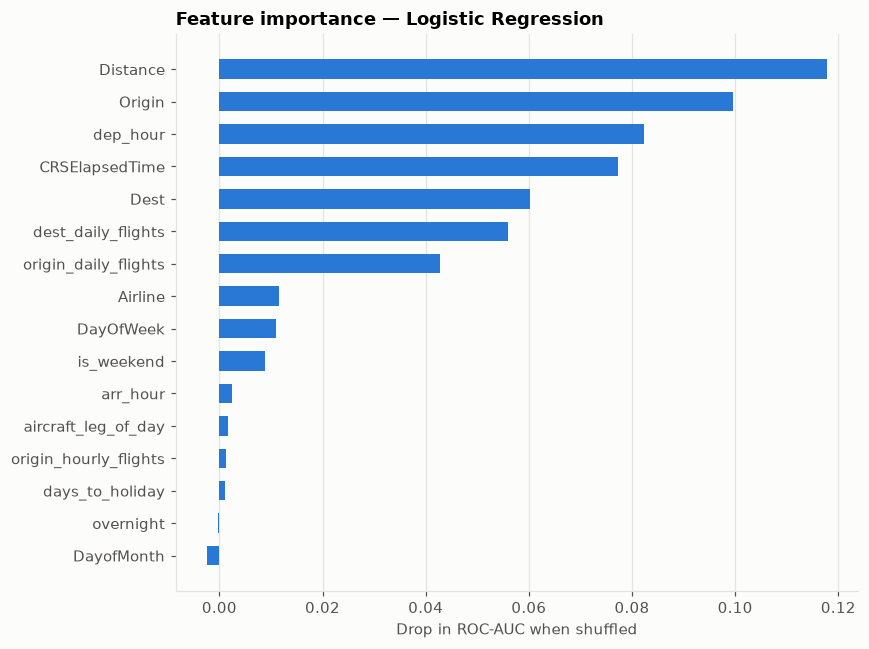

In [25]:
best = order[0]
sub = np.random.default_rng(SEED).choice(len(X_test), size=10_000, replace=False)
imp = permutation_importance(models[best], X_test.iloc[sub], y_true[sub], scoring="roc_auc",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, color=MODEL_COLORS[best], height=0.6)
ax.set_xlabel("Drop in ROC-AUC when shuffled"); ax.set_title(f"Feature importance — {best}")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Phase 5 — Conclusions

1. **Evaluation is chronological:** trained on January–May 2022 and tested on June–July 2022,
   i.e. genuinely future flights.
2. **Logistic Regression (macro F1 0.585, CI 0.581–0.589) and Random Forest (0.582, CI 0.578–0.586)
   are statistically tied for best**, followed by Naive Bayes (0.574), SVM (0.567) and the
   Decision Tree (0.552).
3. **The random split was optimistic.** With the same features, the random 80/20 split gave
   Random Forest a macro F1 of 0.619 and ROC-AUC 0.683; testing on later months drops these to
   0.582 and 0.636. The flexible models (Random Forest, SVM, Decision Tree) lose the most, because
   part of what they learned was specific to the training period. Simpler models generalise better
   over time. (The earlier version also used `Month` as a feature, which pushed the random-split
   score to 0.630; that feature cannot work for unseen future months.)
4. **Delayed-class recall can be traded for precision explicitly.** Optimising delayed-class F1
   instead of macro F1 raises recall from 33% to 56% (delayed F1 0.355 → 0.415); a 70% recall
   target is reachable at about 31% precision; 50% precision is not realistically reachable.
5. **Threshold tuning matters.** At 0.5 the calibrated SVM predicts almost no delays (recall 0.4%);
   every model's operating point should be chosen for a stated objective.
6. **Summer drift:** the test months have a higher delay rate (23.6% vs 20.8%), so thresholds tuned
   on spring data are slightly too high for summer, and ROC-AUC falls for every model.
7. Scores are moderate (ROC-AUC ≈ 0.64, PR-AUC ≈ 0.35 vs 0.24 for random guessing), which is
   realistic for *pre-departure* prediction without weather data.

### Limitations and future work

- Only January–July 2022 is available, so the test period (summer) differs from training (winter/spring).
- No weather or air-traffic-control data, which are the main real causes of delay.
- The SVM is trained on a 25,000-flight subset because kernel SVM scales quadratically.
- Future work: train on several years so every month appears in training, add weather data,
  re-tune thresholds on a recent validation window, and try gradient boosting.